In [1]:
pip install numpy-financial

In [2]:
import pandas as pd
import numpy as np
import numpy_financial as npf
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm

In [3]:
Ventas_24=100000
Incr_Ventas=np.array([0,0.06,0.06,0.08,0.12,0.15])
Inflacion=np.array([0,0.032,0.029,0.025,0.022,0.02])

Incr_Ventas_Acum=np.cumprod(1+Incr_Ventas)
Inflacion_Acum=np.cumprod(1+Inflacion)


Ventas=Ventas_24*(Incr_Ventas_Acum)*(Inflacion_Acum)
print(Ventas)


[100000.         109392.         119318.23008    132085.28069856
 151190.0956988  177345.98225469]


In [4]:
FC = pd.DataFrame(
    [Ventas],
    index=['Ventas'],
    columns=[0, 1, 2, 3, 4, 5]
)
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.0,119318.23008,132085.280699,151190.095699,177345.982255


In [5]:
FC.loc['Variación Ventas']=FC.loc['Ventas'].diff()
FC.loc['Variación Ventas',0]=0
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.0,119318.23008,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.0,9926.23008,12767.050619,19104.815000,26155.886556


In [6]:
Margen=np.array([0,0.2,0.2,0.22,0.24,0.24])
FC.loc['Gastos Operativos']=FC.loc['Variación Ventas']*-(1-Margen)
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.0,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.0,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.6,-7940.984064,-9958.299482,-14519.659400,-19878.473782


# Activo No Corriente
## Inversión en 0

# Infraestructura

In [7]:
Infraestructura_0=5000
Capex_Infra=np.array([0]+[0.015]*5)
Capex_Infra_Acum=np.cumprod(1+Capex_Infra)
print(Capex_Infra_Acum)

VB_Infra=Infraestructura_0*(Capex_Infra_Acum)
print(VB_Infra)

[1.         1.015      1.030225   1.04567837 1.06136355 1.077284  ]
[5000.         5075.         5151.125      5228.391875   5306.81775312
 5386.42001942]


In [8]:
ANC = pd.DataFrame(
    [VB_Infra],
    index=['VB Infraestructura'],
    columns=[0, 1, 2, 3, 4, 5]
)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019


In [9]:
ANC.loc['CAPEX Infraestructura']=ANC.loc['VB Infraestructura'].diff()
ANC.loc['CAPEX Infraestructura',0]=0
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266


In [10]:
Amort_Infra=20
ANC.loc['Amort. Infraestructura'] = (
    ANC.loc['VB Infraestructura'] * (1 / Amort_Infra)
).shift(1).fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888


## Maquinaria

In [11]:
Maquinaria_0=6000
Capex_Maqui=np.array([0]+[0.03]*5)
Capex_Maqui_Acum=np.cumprod(1+Capex_Maqui)
print(Capex_Maqui_Acum)

VB_Maqui=Maquinaria_0*(Capex_Maqui_Acum)
print(VB_Maqui)

[1.         1.03       1.0609     1.092727   1.12550881 1.15927407]
[6000.        6180.        6365.4       6556.362     6753.05286
 6955.6444458]


In [12]:
ANC.loc['VB Maquinaria']=VB_Maqui
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446


In [13]:
ANC.loc['CAPEX Maquinaria']=(ANC.loc['VB Maquinaria']).diff().fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586


In [14]:
Amort_Maqui=10
ANC.loc['Amort. Maquinaria'] = (
    ANC.loc['VB Maquinaria'] * (1 / Amort_Maqui)
).shift(1).fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286


# Sistema de Control

In [15]:
Sist_Control_0=1500
Capex_Sist_Control=np.array([0]+[0.05]*5)
Capex_Sist_Control_Acum=np.cumprod(1+Capex_Sist_Control)
print(Capex_Sist_Control_Acum)

VB_Sist_Control=Sist_Control_0*(Capex_Sist_Control_Acum)
print(VB_Sist_Control)

[1.         1.05       1.1025     1.157625   1.21550625 1.27628156]
[1500.         1575.         1653.75       1736.4375     1823.259375
 1914.42234375]


In [16]:
ANC.loc['VB Sistema de Control']=VB_Sist_Control
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344


In [17]:
ANC.loc['CAPEX Sistema de Control']=(ANC.loc['VB Sistema de Control']).diff().fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969


In [18]:
Amort_Sist_Control=5
ANC.loc['Amort. Sistema de Control'] = (
    ANC.loc['VB Sistema de Control'] * (1 / Amort_Sist_Control)
).shift(1).fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875


# Licencia

In [19]:
Licencia_0=500
Capex_Licencia=np.array([0]+[0.02]*5)
Capex_Licencia_Acum=np.cumprod(1+Capex_Licencia)
print(Capex_Licencia_Acum)

VB_Licencia=Licencia_0*(Capex_Licencia_Acum)
print(VB_Licencia)

[1.         1.02       1.0404     1.061208   1.08243216 1.1040808 ]
[500.        510.        520.2       530.604     541.21608   552.0404016]


In [20]:
ANC.loc['VB Licencia']=VB_Licencia
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [21]:
ANC.loc['CAPEX Licencia']=(ANC.loc['VB Licencia']).diff().fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [22]:
Amort_Licencia=5
ANC.loc['Amort. Licencia'] = (
    ANC.loc['VB Licencia'] * (1 / Amort_Licencia)
).shift(1).fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [23]:
Inver_ANC_0=ANC.sum(axis=0)[0]# Sumar toda la columna 0
ANC.loc['Inversión ANC en año 0']=[-Inver_ANC_0]+[0]*5
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [24]:
ANC.loc['CAPEX año 0']=ANC.loc['CAPEX Infraestructura']+ANC.loc['CAPEX Maquinaria']+ANC.loc['CAPEX Sistema de Control']+ANC.loc['CAPEX Licencia']
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [25]:
ANC.loc['Amort. año 0']=ANC.loc['Amort. Infraestructura']+ANC.loc['Amort. Maquinaria']+ANC.loc['Amort. Sistema de Control']+ANC.loc['Amort. Licencia']
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


## Inversión año 3

# Infraestructura

In [26]:
Infraestructura_3=9615
Capex_Infra_3=np.array([0]+[0.015]*2)
Capex_Infra_Acum_3=np.cumprod(1+Capex_Infra_3)
print(Capex_Infra_Acum_3)

Infra_3=Infraestructura_3*(Capex_Infra_Acum_3)
print(Infra_3)
VB_Infra_3=np.concatenate([np.zeros(3),Infra_3])
print(VB_Infra_3)

[1.       1.015    1.030225]
[9615.       9759.225    9905.613375]
[   0.          0.          0.       9615.       9759.225    9905.613375]


In [27]:
ANC.loc['VB Infraestructura_3']=VB_Infra_3
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [28]:
CAPEX_Infra_3 = (
    ANC.loc['VB Infraestructura_3']
    .iloc[3:]
    .diff()
    .fillna(0)
)
CAPE_Infra_3_v = np.concatenate([np.zeros(3), CAPEX_Infra_3.values])
ANC.loc['CAPEX Infraestructura_3'] = CAPE_Infra_3_v
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [29]:
Amort_Infra_3=25
ANC.loc['Amort. Infraestructura_3'] = (
    ANC.loc['VB Infraestructura_3'] * (1 / Amort_Infra_3)
).shift(1).fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


## Maquinaria

In [30]:
Maqui_3=11538
Capex_Maqui_3=np.array([0]+[0.03]*2)
Capex_Maqui_Acum_3=np.cumprod(1+Capex_Maqui_3)
print(Capex_Maqui_Acum_3)

Maqui_3=Maqui_3*(Capex_Maqui_Acum_3)
print(Maqui_3)
VB_Maqui_3=np.concatenate([np.zeros(3),Maqui_3])
print(VB_Maqui_3)

[1.     1.03   1.0609]
[11538.     11884.14   12240.6642]
[    0.         0.         0.     11538.     11884.14   12240.6642]


In [31]:
ANC.loc['VB Maquinaria_3']=VB_Maqui_3
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [32]:
CAPEX_Maqui_3 = (
    ANC.loc['VB Maquinaria_3']
    .iloc[3:]
    .diff()
    .fillna(0)
)
CAPE_Maqui_3_v = np.concatenate([np.zeros(3), CAPEX_Maqui_3.values])
ANC.loc['CAPEX Maquinaria_3'] = CAPE_Maqui_3_v
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [33]:
Amort_Maqui_3=12
ANC.loc['Amort. Maquinaria_3'] = (
    ANC.loc['VB Maquinaria_3'] * (1 / Amort_Maqui_3)
).shift(1).fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


### Sistema de Control

In [34]:
Sistema_Control_3=2885
Capex_Sistema_Control_3=np.array([0]+[0.05]*2)
Capex_Sistema_Control_Acum_3=np.cumprod(1+Capex_Sistema_Control_3)
print(Capex_Sistema_Control_Acum_3)

Sistema_Control_3=Sistema_Control_3*(Capex_Sistema_Control_Acum_3)
print(Sistema_Control_3)
VB_Sistema_Control_3=np.concatenate([np.zeros(3),Sistema_Control_3])
print(VB_Sistema_Control_3)

[1.     1.05   1.1025]
[2885.     3029.25   3180.7125]
[   0.        0.        0.     2885.     3029.25   3180.7125]


In [35]:
ANC.loc['VB Sistema de Control_3']=VB_Sistema_Control_3
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [36]:
CAPEX_Sist_Control_3 = (
    ANC.loc['VB Sistema de Control_3']
    .iloc[3:]
    .diff()
    .fillna(0)
)
CAPE_Sist_Control_3_v = np.concatenate([np.zeros(3), CAPEX_Sist_Control_3.values])
ANC.loc['CAPEX Sistema de Control_3'] = CAPE_Sist_Control_3_v
ANC


,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [37]:
Amort_Sistema_Control_3=7
ANC.loc['Amort. Sistema de Control_3'] = (
    ANC.loc['VB Sistema de Control_3'] * (1 / Amort_Sistema_Control_3)
).shift(1).fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


### Licencia

In [38]:
Licencia_3=962
Capex_Licencia_3=np.array([0]+[0.02]*2)
Capex_Licencia_Acum_3=np.cumprod(1+Capex_Licencia_3)
print(Capex_Licencia_Acum_3)

Licencia_3=Licencia_3*(Capex_Licencia_Acum_3)
print(Licencia_3)
VB_Licencia_3=np.concatenate([np.zeros(3),Licencia_3])
print(VB_Licencia_3)

[1.     1.02   1.0404]
[ 962.      981.24   1000.8648]
[   0.        0.        0.      962.      981.24   1000.8648]


In [39]:
ANC.loc['VB Licencia_3']=VB_Licencia_3
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [40]:
CAPEX_Licencia_3 = (
    ANC.loc['VB Licencia_3']
    .iloc[3:]
    .diff()
    .fillna(0)
)
CAPE_Licencia_3_v = np.concatenate([np.zeros(3), CAPEX_Licencia_3.values])
ANC.loc['CAPEX Licencia_3'] = CAPE_Licencia_3_v
ANC


,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [41]:
Amort_Licencia_3=5
ANC.loc['Amort. Licencia_3'] = (
    ANC.loc['VB Licencia_3'] * (1 / Amort_Licencia_3)
).shift(1).fillna(0)
ANC

,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


In [42]:
Inver_ANC_3=-(ANC.loc['VB Infraestructura_3',3]
               +ANC.loc['VB Maquinaria_3',3]
               +ANC.loc['VB Sistema de Control_3',3]
               +ANC.loc['VB Licencia_3',3]
              )
ANC.loc['Inversión ANC año 3']=[0]*3+[Inver_ANC_3]+[0]*2
ANC.loc['CAPEX año 3']=(ANC.loc['CAPEX Infraestructura_3']
                         +ANC.loc['CAPEX Maquinaria_3']
                         +ANC.loc['CAPEX Sistema de Control_3']
                         +ANC.loc['CAPEX Licencia_3']
                         )
ANC.loc['Amort. año 3']=(ANC.loc['Amort. Infraestructura_3']
                          +ANC.loc['Amort. Maquinaria_3']
                          +ANC.loc['Amort. Sistema de Control_3']
                          +ANC.loc['Amort. Licencia_3']
                         )


ANC.loc['CAPEX']=ANC.loc['CAPEX año 0']+ANC.loc['CAPEX año 3']
ANC.loc['Amort.']=ANC.loc['Amort. año 0']+ANC.loc['Amort. año 3']
ANC.loc['Inversión']=ANC.loc['Inversión ANC en año 0']+ANC.loc['Inversión ANC año 3']

ANC


,0,1,2,3,4,5
VB Infraestructura,5000.0,5075.0,5151.125,5228.391875,5306.817753,5386.420019
CAPEX Infraestructura,0.0,75.0,76.125,77.266875,78.425878,79.602266
Amort. Infraestructura,0.0,250.0,253.750,257.556250,261.419594,265.340888
VB Maquinaria,6000.0,6180.0,6365.400,6556.362000,6753.052860,6955.644446
CAPEX Maquinaria,0.0,180.0,185.400,190.962000,196.690860,202.591586
Amort. Maquinaria,0.0,600.0,618.000,636.540000,655.636200,675.305286
VB Sistema de Control,1500.0,1575.0,1653.750,1736.437500,1823.259375,1914.422344
CAPEX Sistema de Control,0.0,75.0,78.750,82.687500,86.821875,91.162969
Amort. Sistema de Control,0.0,300.0,315.000,330.750000,347.287500,364.651875
VB Licencia,500.0,510.0,520.200,530.604000,541.216080,552.040402


# Beneficio Neto

In [43]:
FC.loc['Amortización']=-ANC.loc['Amort.']
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.0,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.0,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.6,-7940.984064,-9958.299482,-14519.659400,-19878.473782
Amortización,-0.0,-1250.0,-1288.750000,-1328.886250,-3321.106951,-3423.253265


In [44]:
Dir_Tecn=1200
Finan=600
IT=800
Costes=400
Coste_Staff_3=Dir_Tecn+Finan+IT+Costes
Coste_Staff_4=Coste_Staff_3*(1+Inflacion[-1])

Coste_Staff_v = np.concatenate([
    np.zeros(4),
    np.array([Coste_Staff_3, Coste_Staff_4])
])
FC.loc['Coste Staff']=-Coste_Staff_v

FC

,0,1,2,3,4,5
Ventas,100000.0,109392.0,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.0,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.6,-7940.984064,-9958.299482,-14519.659400,-19878.473782
Amortización,-0.0,-1250.0,-1288.750000,-1328.886250,-3321.106951,-3423.253265
Coste Staff,-0.0,-0.0,-0.000000,-0.000000,-3000.000000,-3060.000000


In [45]:
Capacitacion=[0]+[-1000]+[0]+[-3000]+[0]*2
FC.loc['Capacitación']=Capacitacion
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.0,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.0,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.6,-7940.984064,-9958.299482,-14519.659400,-19878.473782
Amortización,-0.0,-1250.0,-1288.750000,-1328.886250,-3321.106951,-3423.253265
Coste Staff,-0.0,-0.0,-0.000000,-0.000000,-3000.000000,-3060.000000
Capacitación,0.0,-1000.0,0.000000,-3000.000000,0.000000,0.000000


In [46]:
FC.loc['BAIT']=(FC.loc['Variación Ventas']
                +FC.loc['Gastos Operativos']
                +FC.loc['Amortización']
                +FC.loc['Coste Staff']
                +FC.loc['Capacitación'])
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.0,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.0,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.6,-7940.984064,-9958.299482,-14519.659400,-19878.473782
Amortización,-0.0,-1250.0,-1288.750000,-1328.886250,-3321.106951,-3423.253265
Coste Staff,-0.0,-0.0,-0.000000,-0.000000,-3000.000000,-3060.000000
Capacitación,0.0,-1000.0,0.000000,-3000.000000,0.000000,0.000000
BAIT,0.0,-371.6,696.496016,-1520.135114,-1735.951351,-205.840491


In [47]:
Tipo_impostivo=0.20
FC.loc['Beneficio Neto']=FC.loc['BAIT']*(1-Tipo_impostivo)
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.00,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.00,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.60,-7940.984064,-9958.299482,-14519.659400,-19878.473782
Amortización,-0.0,-1250.00,-1288.750000,-1328.886250,-3321.106951,-3423.253265
Coste Staff,-0.0,-0.00,-0.000000,-0.000000,-3000.000000,-3060.000000
Capacitación,0.0,-1000.00,0.000000,-3000.000000,0.000000,0.000000
BAIT,0.0,-371.60,696.496016,-1520.135114,-1735.951351,-205.840491
Beneficio Neto,0.0,-297.28,557.196813,-1216.108091,-1388.761081,-164.672393


# Flujo de caja

In [48]:
#Existencias
PME=120 # Gastos Operativos

Existencias = pd.DataFrame(
    columns=[0, 1, 2, 3, 4, 5]
)
Existencias.loc['E.Iniciales']=[0]* (len(FC.loc['Gastos Operativos']))
Existencias.loc['E.Finales']=-FC.loc['Gastos Operativos']*(PME/360)

for t in range(1, len(FC.columns)):
    Existencias.loc['E.Iniciales', t] = Existencias.loc['E.Finales', t-1]


Existencias.loc['E.Var']=Existencias.loc['E.Finales']-Existencias.loc['E.Iniciales']
Existencias

,0,1,2,3,4,5
E.Iniciales,0.0,0.000000,2504.533333,2646.994688,3319.433161,4839.886467
E.Finales,0.0,2504.533333,2646.994688,3319.433161,4839.886467,6626.157927
E.Var,0.0,2504.533333,142.461355,672.438473,1520.453306,1786.271461


In [49]:
#Clientes

PMC=90
Clientes = pd.DataFrame(
    columns=[0, 1, 2, 3, 4, 5]
)
Clientes.loc['C.Iniciales']=[0]* (len(FC.loc['Variación Ventas']))
Clientes.loc['C.Finales']=FC.loc['Variación Ventas']/360*PMC

for t in range(1, len(FC.columns)):
    Clientes.loc['C.Iniciales', t] = Clientes.loc['C.Finales', t-1]

Clientes.loc['C.Var']=Clientes.loc['C.Finales']-Clientes.loc['C.Iniciales']
Clientes

,0,1,2,3,4,5
C.Iniciales,0.0,0.0,2348.00000,2481.557520,3191.762655,4776.203750
C.Finales,0.0,2348.0,2481.55752,3191.762655,4776.203750,6538.971639
C.Var,0.0,2348.0,133.55752,710.205135,1584.441095,1762.767889


In [50]:
#Proveedores

PMP=75 # días de Gastos Operativos
Proveedores = pd.DataFrame(
    columns=[0, 1, 2, 3, 4, 5]
)
Proveedores.loc['P.Iniciales']=[0]* (len(FC.loc['Gastos Operativos']))
Proveedores.loc['P.Finales']=-FC.loc['Gastos Operativos']/360*PMP

for t in range(1, len(FC.columns)):
    Proveedores.loc['P.Iniciales', t] = Proveedores.loc['P.Finales', t-1]

Proveedores.loc['P.Var']=Proveedores.loc['P.Finales']-Proveedores.loc['P.Iniciales']
Proveedores

,0,1,2,3,4,5
P.Iniciales,0.0,0.000000,1565.333333,1654.371680,2074.645726,3024.929042
P.Finales,0.0,1565.333333,1654.371680,2074.645726,3024.929042,4141.348705
P.Var,0.0,1565.333333,89.038347,420.274046,950.283316,1116.419663


In [51]:
FC.loc['Var Fondo de Maniobra']=Clientes.loc['C.Var']-Proveedores.loc['P.Var']+Existencias.loc['E.Var']
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.00,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.00,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.60,-7940.984064,-9958.299482,-14519.659400,-19878.473782
Amortización,-0.0,-1250.00,-1288.750000,-1328.886250,-3321.106951,-3423.253265
Coste Staff,-0.0,-0.00,-0.000000,-0.000000,-3000.000000,-3060.000000
Capacitación,0.0,-1000.00,0.000000,-3000.000000,0.000000,0.000000
BAIT,0.0,-371.60,696.496016,-1520.135114,-1735.951351,-205.840491
Beneficio Neto,0.0,-297.28,557.196813,-1216.108091,-1388.761081,-164.672393
Var Fondo de Maniobra,0.0,3287.20,186.980528,962.369562,2154.611085,2432.619687


In [52]:
FC.loc['Subvenciones']=[0]*2+[108000]+[0]*3
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.00,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.00,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.60,-7940.984064,-9958.299482,-14519.659400,-19878.473782
Amortización,-0.0,-1250.00,-1288.750000,-1328.886250,-3321.106951,-3423.253265
Coste Staff,-0.0,-0.00,-0.000000,-0.000000,-3000.000000,-3060.000000
Capacitación,0.0,-1000.00,0.000000,-3000.000000,0.000000,0.000000
BAIT,0.0,-371.60,696.496016,-1520.135114,-1735.951351,-205.840491
Beneficio Neto,0.0,-297.28,557.196813,-1216.108091,-1388.761081,-164.672393
Var Fondo de Maniobra,0.0,3287.20,186.980528,962.369562,2154.611085,2432.619687
Subvenciones,0.0,0.00,108000.000000,0.000000,0.000000,0.000000


In [53]:
FC.loc['Inversión ANC']=ANC.loc['Inversión']
FC.loc['CAPEX']=-ANC.loc['CAPEX']
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.00,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.00,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.60,-7940.984064,-9958.299482,-14519.659400,-19878.473782
Amortización,-0.0,-1250.00,-1288.750000,-1328.886250,-3321.106951,-3423.253265
Coste Staff,-0.0,-0.00,-0.000000,-0.000000,-3000.000000,-3060.000000
Capacitación,0.0,-1000.00,0.000000,-3000.000000,0.000000,0.000000
BAIT,0.0,-371.60,696.496016,-1520.135114,-1735.951351,-205.840491
Beneficio Neto,0.0,-297.28,557.196813,-1216.108091,-1388.761081,-164.672393
Var Fondo de Maniobra,0.0,3287.20,186.980528,962.369562,2154.611085,2432.619687
Subvenciones,0.0,0.00,108000.000000,0.000000,0.000000,0.000000


In [54]:
FC.loc['FCF']=(FC.loc['Beneficio Neto']
               -FC.loc['Amortización']
               -FC.loc['Var Fondo de Maniobra']
               +FC.loc['Subvenciones']
               +FC.loc['Inversión ANC']
               +FC.loc['CAPEX'])
FC

,0,1,2,3,4,5
Ventas,100000.0,109392.00,119318.230080,132085.280699,151190.095699,177345.982255
Variación Ventas,0.0,9392.00,9926.230080,12767.050619,19104.815000,26155.886556
Gastos Operativos,-0.0,-7513.60,-7940.984064,-9958.299482,-14519.659400,-19878.473782
Amortización,-0.0,-1250.00,-1288.750000,-1328.886250,-3321.106951,-3423.253265
Coste Staff,-0.0,-0.00,-0.000000,-0.000000,-3000.000000,-3060.000000
Capacitación,0.0,-1000.00,0.000000,-3000.000000,0.000000,0.000000
BAIT,0.0,-371.60,696.496016,-1520.135114,-1735.951351,-205.840491
Beneficio Neto,0.0,-297.28,557.196813,-1216.108091,-1388.761081,-164.672393
Var Fondo de Maniobra,0.0,3287.20,186.980528,962.369562,2154.611085,2432.619687
Subvenciones,0.0,0.00,108000.000000,0.000000,0.000000,0.000000


# Coste de Capital

In [55]:
B_u=0.77
E=0.4
D=1-E
RM=0.1
RF=0.03
B_e=B_u*(1+(D*(1-Tipo_impostivo)/E))
print('Beta apalandacada:',B_e)

k_e=RF+B_e*(RM-RF)
print('Coste del Equity:',k_e)

k_d=0.05
k=k_e*E+k_d*(1-Tipo_impostivo)*D
print('Coste de capital Nominal año 0:',k)

k_r=(1+k)/(1+Inflacion[1])-1
print('Coste de capital Real año 0:',k_r)

K_n=(1+k_r)*(1+Inflacion)-1
K_n[0]=0
print('Coste de capital Nominal:',K_n)

K_n_acum=np.cumprod(1+K_n)
print('Coste de capital Nominal Acumulado:',K_n_acum)

Beta apalandacada: 1.6940000000000002
Coste del Equity: 0.14858000000000002
Coste de capital Nominal año 0: 0.08343200000000002
Coste de capital Real año 0: 0.0498372093023256
Coste de capital Nominal: [0.         0.083432   0.08028249 0.07608314 0.07293363 0.07083395]
Coste de capital Nominal Acumulado: [1.         1.083432   1.17041262 1.25946128 1.35131836 1.44703759]


In [56]:
g=0.04
FC_6=FC.loc['FCF'].iloc[-1]*(1+g)
print('Flujo de Caja año 6:',FC_6)

VR=FC_6/(K_n[-1]-g)
print('Valor Residual:',VR)

Flujo de Caja año 6: -241.50862578383305
Valor Residual: -7832.554650343771


In [57]:
FCF=FC.loc['FCF']
FCF.iloc[-1]+=VR
FCF

,FCF
0,-13000.000000
1,-2674.480000
2,109308.491285
3,-26210.911778
4,-1248.670908
5,-8064.774483


In [58]:
VAN=FCF@(1/K_n_acum)
VAN

np.float64(50616.050796950694)

In [59]:
TIR=npf.irr(FCF)
TIR

-0.4600962996850284

In [60]:
# Estimamos los saldos
S = []

for i in range(len(FCF)):
    if i == 0:
        S.append(FCF[i])
    else:
        S.append(S[i-1] * (1 + TIR)+FCF[i])

S

[np.float64(-13000.0),
 np.float64(-9693.228104094629),
 np.float64(104075.08156340223),
 np.float64(29979.6098685803),
 np.float64(14937.43139401225),
 np.float64(1.2732925824820995e-11)]

In [61]:
# Estimamos la TMR
#REINVERSIÓN
k_RI=K_n_acum[-1]/K_n_acum
print(k_RI)
FCN=FCF[2]*k_RI[2]
print('FLujo de Caja en N:',FCN)

#INVERSIÓN
k_F=1/K_n_acum
k_F[2]=0
print('Factor de descuento:',k_F)

Inversion_Total=FCF@k_F
print('Inversión Inicial:',Inversion_Total)

FCF_TMR=[Inversion_Total]+[0]*4+[FCN]
TMR=npf.irr(FCF_TMR)
print('TMR:',TMR)

[1.44703759 1.33560536 1.23634825 1.14893376 1.07083395 1.        ]
FLujo de Caja en N: 135143.36148099293
Factor de descuento: [1.         0.92299286 0.         0.79399027 0.74001806 0.69106705]
Inversión Inicial: -42777.07373241447
TMR: 0.2586840502798733


In [62]:
#ESCENARIOS
escenarios = {
    'Pesimista': {'Ventas': 0.8 },
    'Normal':    {'Ventas': 1.0,},
    'Optimista': {'Ventas': 1.2}
}

In [63]:
FC_Base=FC.copy()
Cliente_Base=Clientes.copy()
Existencia_Base=Existencias.copy()
Proveedor_Base=Proveedores.copy()

In [64]:
def recalcular_FC(FC_base, mult_ventas):
    FC = FC_Base.copy()
    Clientes = Cliente_Base.copy()
    Existencias = Existencia_Base.copy()
    Proveedores = Proveedor_Base.copy()
    Ventas_24=100000
    Incr_Ventas=np.array([0,0.06,0.06,0.08,0.12,0.15])*mult_ventas
    Inflacion=np.array([0,0.032,0.029,0.025,0.022,0.02])

    Incr_Ventas_Acum=np.cumprod(1+Incr_Ventas)
    Inflacion_Acum=np.cumprod(1+Inflacion)


    Ventas=Ventas_24*(Incr_Ventas_Acum)*(Inflacion_Acum)
    FC.loc['Ventas'] = Ventas
    FC.loc['Variación Ventas']=FC.loc['Ventas'].diff()
    FC.loc['Variación Ventas',0]=0
    FC.loc['Gastos Operativos']=FC.loc['Variación Ventas']*-(1-Margen)
    FC.loc['BAIT']=(FC.loc['Variación Ventas']
                +FC.loc['Gastos Operativos']
                +FC.loc['Amortización']
                +FC.loc['Coste Staff']
                +FC.loc['Capacitación'])
    FC.loc['Beneficio Neto']=FC.loc['BAIT']*(1-Tipo_impostivo)
    Existencias.loc['E.Iniciales']=[0]* (len(FC.loc['Gastos Operativos']))
    Existencias.loc['E.Finales']=-FC.loc['Gastos Operativos']*(PME/360)

    for t in range(1, len(FC.columns)):
        Existencias.loc['E.Iniciales', t] = Existencias.loc['E.Finales', t-1]


    Existencias.loc['E.Var']=Existencias.loc['E.Finales']-Existencias.loc['E.Iniciales']
    Clientes.loc['C.Iniciales']=[0]* (len(FC.loc['Variación Ventas']))
    Clientes.loc['C.Finales']=FC.loc['Variación Ventas']/360*PMC

    for t in range(1, len(FC.columns)):
        Clientes.loc['C.Iniciales', t] = Clientes.loc['C.Finales', t-1]

    Clientes.loc['C.Var']=Clientes.loc['C.Finales']-Clientes.loc['C.Iniciales']
    Proveedores.loc['P.Iniciales']=[0]* (len(FC.loc['Gastos Operativos']))
    Proveedores.loc['P.Finales']=-FC.loc['Gastos Operativos']/360*PMP

    for t in range(1, len(FC.columns)):
        Proveedores.loc['P.Iniciales', t] = Proveedores.loc['P.Finales', t-1]

    Proveedores.loc['P.Var']=Proveedores.loc['P.Finales']-Proveedores.loc['P.Iniciales']
    FC.loc['Var Fondo de Maniobra']=Clientes.loc['C.Var']-Proveedores.loc['P.Var']+Existencias.loc['E.Var']
    FC.loc['FCF']=(FC.loc['Beneficio Neto']
               -FC.loc['Amortización']
               -FC.loc['Var Fondo de Maniobra']
               +FC.loc['Subvenciones']
               +FC.loc['Inversión ANC']
               +FC.loc['CAPEX'])
    FC_6=FC.loc['FCF'].iloc[-1]*(1+g)
    VR=FC_6/(K_n[-1]-g)
    FCF=FC.loc['FCF']
    FCF.iloc[-1]+=VR
    VAN=FCF@(1/K_n_acum)

    return VAN

In [65]:
VAN_neutro = recalcular_FC(FC_Base, 1)
VAN_neutro

np.float64(50616.050796950694)

In [66]:
VAN_pesimista = recalcular_FC(FC_Base, 0.8)
VAN_optimista = recalcular_FC(FC_Base, 1.2)
print(f'VAN pesimista: {VAN_pesimista}')
print(f'VAN optimista: {VAN_optimista}')

VAN pesimista: 40321.71533304738
VAN optimista: 60807.55114549663


In [67]:
ventas_base = Incr_Ventas
T = len(ventas_base)

In [68]:
# Sigma crece con el tiempo
sigma_base = 0.1  # 10% incertidumbre inicial

sigma_t = sigma_base * (1 + np.arange(T))  # crece con t
sigma_t

array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6])

In [69]:
n_sim = 5000

ventas_sim = np.zeros((n_sim, T))

for t in range(T):
    if t == 0:
        ventas_sim[:, t] = 0 # Damos valor 0 al momento 0
    else:
        ventas_sim[:, t] = np.random.normal(
            loc=ventas_base[t], # media
            scale=sigma_t[t] * ventas_base[t], #desv típica
            size=n_sim
        )

In [70]:
# Todas las ventas tienen que ser mayor o igual a 0
ventas_sim = np.maximum(ventas_sim, 0)

In [76]:
def recalcular_FC_sim(ventas_sim):
    FC = FC_Base.copy()
    Clientes = Cliente_Base.copy()
    Existencias = Existencia_Base.copy()
    Proveedores = Proveedor_Base.copy()
    Ventas_24=100000
    Incr_Ventas= ventas_sim
    Inflacion=np.array([0,0.032,0.029,0.025,0.022,0.02])

    Incr_Ventas_Acum=np.cumprod(1+Incr_Ventas)
    Inflacion_Acum=np.cumprod(1+Inflacion)


    Ventas=Ventas_24*(Incr_Ventas_Acum)*(Inflacion_Acum)
    FC.loc['Ventas'] = Ventas
    FC.loc['Variación Ventas']=FC.loc['Ventas'].diff()
    FC.loc['Variación Ventas',0]=0
    FC.loc['Gastos Operativos']=FC.loc['Variación Ventas']*-(1-Margen)
    FC.loc['BAIT']=(FC.loc['Variación Ventas']
                +FC.loc['Gastos Operativos']
                +FC.loc['Amortización']
                +FC.loc['Coste Staff']
                +FC.loc['Capacitación'])
    FC.loc['Beneficio Neto']=FC.loc['BAIT']*(1-Tipo_impostivo)
    Existencias.loc['E.Iniciales']=[0]* (len(FC.loc['Gastos Operativos']))
    Existencias.loc['E.Finales']=-FC.loc['Gastos Operativos']*(PME/360)

    for t in range(1, len(FC.columns)):
        Existencias.loc['E.Iniciales', t] = Existencias.loc['E.Finales', t-1]


    Existencias.loc['E.Var']=Existencias.loc['E.Finales']-Existencias.loc['E.Iniciales']
    Clientes.loc['C.Iniciales']=[0]* (len(FC.loc['Variación Ventas']))
    Clientes.loc['C.Finales']=FC.loc['Variación Ventas']/360*PMC

    for t in range(1, len(FC.columns)):
        Clientes.loc['C.Iniciales', t] = Clientes.loc['C.Finales', t-1]

    Clientes.loc['C.Var']=Clientes.loc['C.Finales']-Clientes.loc['C.Iniciales']
    Proveedores.loc['P.Iniciales']=[0]* (len(FC.loc['Gastos Operativos']))
    Proveedores.loc['P.Finales']=-FC.loc['Gastos Operativos']/360*PMP

    for t in range(1, len(FC.columns)):
        Proveedores.loc['P.Iniciales', t] = Proveedores.loc['P.Finales', t-1]

    Proveedores.loc['P.Var']=Proveedores.loc['P.Finales']-Proveedores.loc['P.Iniciales']
    FC.loc['Var Fondo de Maniobra']=Clientes.loc['C.Var']-Proveedores.loc['P.Var']+Existencias.loc['E.Var']
    FC.loc['FCF']=(FC.loc['Beneficio Neto']
               -FC.loc['Amortización']
               -FC.loc['Var Fondo de Maniobra']
               +FC.loc['Subvenciones']
               +FC.loc['Inversión ANC']
               +FC.loc['CAPEX'])
    FC_6=FC.loc['FCF'].iloc[-1]*(1+g)
    VR=FC_6/(K_n[-1]-g)
    FCF=FC.loc['FCF']
    FCF.iloc[-1]+=VR


    return FCF


In [82]:
van_sim = []

for i in range(n_sim):

    # FCF simulados
    FCF = recalcular_FC_sim(ventas_sim[i])

    # VAN usando el descuento base
    van = FCF.values @ (1 / K_n_acum)

    van_sim.append(van)

van_sim = pd.Series(van_sim)

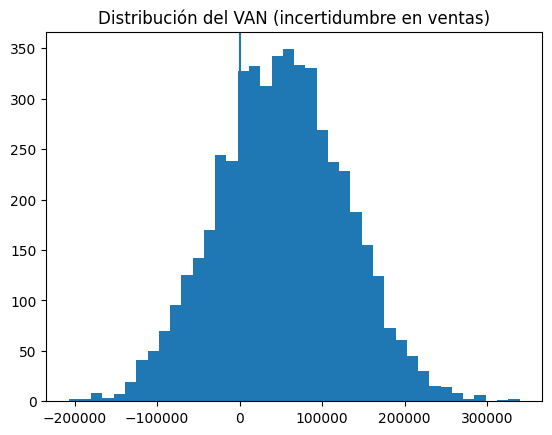

In [83]:
plt.hist(van_sim, bins=40)
plt.axvline(0)
plt.title('Distribución del VAN (incertidumbre en ventas)')
plt.show()

##Intoduzco dependencia temporal

$$𝑉𝑒𝑛𝑡𝑎𝑠_𝑡=𝜇𝑡+𝜌(𝑉𝑒𝑛𝑡𝑎𝑠_{𝑡−1}−𝜇_{𝑡−1})+𝜀_𝑡$$

𝜇𝑡 : ventas esperadas
𝜌 : corelación o persistencia
𝜀𝑡 : shock aleatorio


In [84]:
rho = 0.6        # persistencia (ajusta entre 0 y 1)
n_sim = 5000
T = len(ventas_base)

In [85]:
ventas_sim = np.zeros((n_sim, T))

for i in range(n_sim):
    for t in range(T):

        if t == 0:
            ventas_sim[i, t] = 0 # para t=0 las ventas son 0

        elif t == 1:
            # primer año aleatorio alrededor de la media
            ventas_sim[i, t] = np.random.normal(
                loc=ventas_base[t],# media
                scale=sigma_t[t] * ventas_base[t] #desviación típica
            )

        else:
            shock = np.random.normal( # epsilon
                loc=0,# media
                scale=sigma_t[t] * ventas_base[t] # desviación típica
            )

            ventas_sim[i, t] = (
                ventas_base[t]
                + rho * (ventas_sim[i, t-1] - ventas_base[t-1])
                + shock
            )
            ventas_sim[i, t] = max(0, ventas_sim[i, t]) #evitamos efectos no deseados de ventas negativas

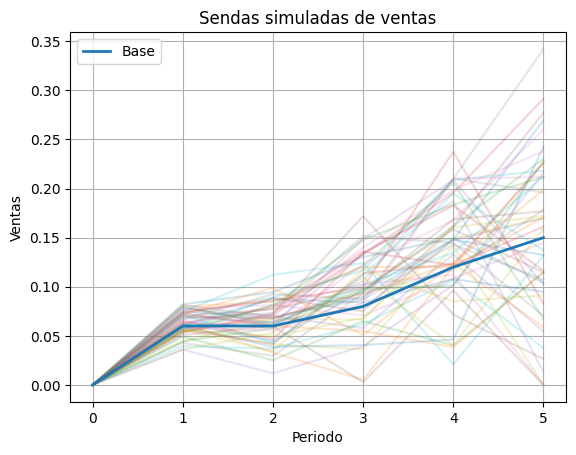

In [86]:
plt.figure()

# Dibujar algunas simulaciones (para no saturar el gráfico)
n_paths = 50

for i in range(n_paths):
    plt.plot(FC.columns, ventas_sim[i], alpha=0.2)

# Trayectoria base
plt.plot(FC.columns, ventas_base, linewidth=2, label='Base')

plt.title('Sendas simuladas de ventas')
plt.xlabel('Periodo')
plt.ylabel('Ventas')
plt.legend()
plt.grid()
